<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_ap_bola.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI, apêndice: a bola que rola

## Rolar uma bola por um caminho fechado e encontrá-la girada: o colchete de Lie que se sente com a mão

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X6_quaternions.ipynb](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb))

**A experiência.** Ponha uma bola sobre a mesa, com uma marca no topo. Role-a, sem deixar escorregar e sem girá-la em torno da vertical, ao longo de um quadrado: um palmo para a frente, um para a direita, um para trás, um para a esquerda. A bola volta ao mesmo lugar, mas **não** à mesma orientação: ela girou em torno da vertical. Rolar em $x$ e rolar em $y$ não comutam, e a diferença entre as duas ordens é um giro em torno de $z$, a direção que nenhum dos dois movimentos produz sozinho. É o colchete de Lie do notebook VI(c), $[\hat{\mathbf x},\hat{\mathbf y}]=\hat{\mathbf z}$, que se pode sentir com a mão.

**O modelo.** Uma esfera de raio $r$ rola sem escorregar sobre o plano $z=0$, com o centro andando com velocidade $\mathbf v$ (horizontal) e sem giro em torno da vertical. O ponto de contato tem velocidade zero, $\mathbf v+\boldsymbol\omega\times(-r\hat{\mathbf z})=0$, o que dá

$$\boldsymbol\omega=\frac{\hat{\mathbf z}\times\mathbf v}{r}\quad\text{(no mundo)},\qquad \dot q=\tfrac12\,(0,\boldsymbol\omega)\otimes q.$$

A velocidade angular está no referencial do **mundo**, e por isso multiplica $q$ pela **esquerda** (no notebook VI(c), o giroscópio media no corpo e multiplicava pela direita). Em cada pequeno trecho reto do caminho, $\boldsymbol\omega$ é constante, e o passo é exato: $q\leftarrow\mathrm{Exp}\big((\hat{\mathbf z}\times\Delta\mathbf c)/r\big)\,q$.

**O resultado a conferir.** Para um caminho fechado pequeno, que cerca uma área $A$ (no sentido anti-horário), a bola volta girada de

$$\lvert\theta\rvert\approx\frac A{r^2}$$

em torno da vertical, **no sentido contrário** ao do caminho (o sinal de menos abaixo), e **qualquer que seja a forma** do caminho. Com o sinal: $\theta\approx-A/r^2$. Para caminhos grandes, o eixo do giro final deixa de ser vertical.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

r = 1.0
Z = np.array([0, 0, 1.0])

def rola(pontos, q0=np.array([1.0, 0, 0, 0])):
    """Rola a bola pelos pontos (complexos) do caminho do centro; devolve as orientações."""
    qs = [q0]
    for p0, p1 in zip(pontos[:-1], pontos[1:]):
        d = p1 - p0
        qs.append(qmul(qexp(np.cross(Z, [d.real, d.imag, 0.0]) / r), qs[-1]))
    return np.array(qs)

# rolar em linha reta uma distância d gira a bola d/r em torno do eixo horizontal perpendicular
d = 0.7
q_reta = rola(np.linspace(0, d, 50) + 0j)[-1]
confere("rolar em reta: giro de d/r em torno de y (andando em +x)", qlog(q_reta), [0, d / r, 0], tol=1e-14)
# o ponto da bola que toca o chão (−r ẑ, no mundo) tem velocidade zero
v = np.array([0.3, -0.4, 0]); w = np.cross(Z, v) / r
confere("o ponto de contato não escorrega", v + np.cross(w, -r * Z), 0, tol=1e-16)

OK   rolar em reta: giro de d/r em torno de y (andando em +x):  diferença máxima = 1.67e-15
OK   o ponto de contato não escorrega:  diferença máxima = 0.00e+00


## 1. O quadrado: um colchete de Lie

Rolar uma distância $a$ em $+x$, depois $+y$, depois $-x$, depois $-y$. São quatro rotações exatas: $\mathrm{Exp}(-\tfrac ar\hat{\mathbf x})\,\mathrm{Exp}(-\tfrac ar\hat{\mathbf y})\,\mathrm{Exp}(\tfrac ar\hat{\mathbf x})\,\mathrm{Exp}(\tfrac ar\hat{\mathbf y})$, um **comutador de grupo**. Para $a$ pequeno, ele vale $\mathrm{Exp}\big(\tfrac{a^2}{r^2}[\hat{\mathbf y},\hat{\mathbf x}]\big)+O(a^3)$, um giro de $a^2/r^2$ (a área do quadrado sobre $r^2$) em torno de $\pm\hat{\mathbf z}$.

In [2]:
print("   a/r     giro em torno de z     área/r²      razão      inclinação do eixo")
razoes = []
for a in [0.02, 0.05, 0.1, 0.2, 0.5, 1.0]:
    quadrado = np.array([0, a, a + 1j * a, 1j * a, 0])
    pts = np.concatenate([np.linspace(quadrado[k], quadrado[k + 1], 2) [:-1] for k in range(4)] + [[0j]])
    q = rola(pts)[-1]
    phi = qlog(q); giro = phi[2]; incl = np.degrees(np.arccos(abs(phi[2]) / np.linalg.norm(phi)))
    razoes.append(giro / (a**2 / r**2))
    print(f"{a:6.2f}      {giro:+.6e}        {a**2 / r**2:.6e}     {giro / (a**2 / r**2):.5f}      {incl:6.2f}°")
confere("para um quadrado pequeno (percorrido no sentido anti-horário), o giro em torno de z é −área/r²", razoes[0], -1, tol=1e-3)

   a/r     giro em torno de z     área/r²      razão      inclinação do eixo
  0.02      -3.999467e-04        4.000000e-04     -0.99987        0.81°
  0.05      -2.497918e-03        2.500000e-03     -0.99917        2.03°
  0.10      -9.966753e-03        1.000000e-02     -0.99668        4.05°
  0.20      -3.947212e-02        4.000000e-02     -0.98680        8.08°
  0.50      -2.304247e-01        2.500000e-01     -0.92170       19.86°
  1.00      -7.341161e-01        1.000000e+00     -0.73412       37.69°
OK   para um quadrado pequeno (percorrido no sentido anti-horário), o giro em torno de z é −área/r²:  diferença máxima = 1.33e-04


## 2. A forma não importa (para caminhos pequenos)

Quatro caminhos com a **mesma área** $A=0{,}004\,r^2$: um círculo, um quadrado, um triângulo equilátero e uma elipse alongada (5 por 1). Todos percorridos no sentido anti-horário, com 2000 pontos.

círculo     : área 0.00400;  giro em torno de z -0.003996 rad  (área/r² = 0.004000);  componentes horizontais 1.4e-04


quadrado    : área 0.00400;  giro em torno de z -0.003995 rad  (área/r² = 0.004000);  componentes horizontais 1.8e-04
triângulo   : área 0.00400;  giro em torno de z -0.003992 rad  (área/r² = 0.004000);  componentes horizontais 2.2e-04


elipse 5:1  : área 0.00400;  giro em torno de z -0.003984 rad  (área/r² = 0.004000);  componentes horizontais 3.2e-04
OK   os quatro caminhos dão o mesmo giro, −área/r², a menos de 1%:  diferença relativa máxima = 4.01e-03


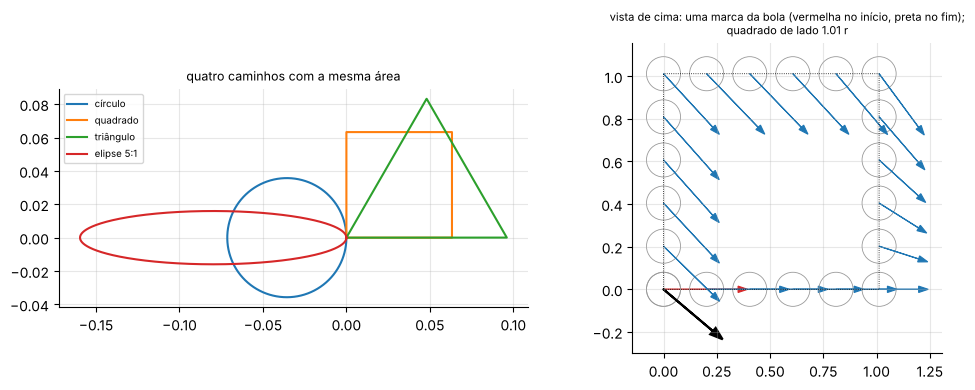

In [3]:
A = 0.004 * r**2
s = np.linspace(0, 1, 2001)
def poligono(vertices, n=2000):
    v_ = np.array(vertices + [vertices[0]]); L_ = np.abs(np.diff(v_)); cum = np.concatenate([[0], np.cumsum(L_)]) / L_.sum()
    return np.interp(s, cum, v_.real) + 1j * np.interp(s, cum, v_.imag)
lado_tri = np.sqrt(4 * A / np.sqrt(3))
caminhos = {
    "círculo": np.sqrt(A / np.pi) * (np.exp(2j * np.pi * s) - 1),
    "quadrado": poligono([0, np.sqrt(A), np.sqrt(A) * (1 + 1j), 1j * np.sqrt(A)]),
    "triângulo": poligono([0, lado_tri, lado_tri * np.exp(1j * np.pi / 3)]),
    "elipse 5:1": np.sqrt(A / np.pi) * (np.sqrt(5) * (np.cos(2 * np.pi * s) - 1) + 1j * np.sin(2 * np.pi * s) / np.sqrt(5)),
}
giros = {}
for nome, cam in caminhos.items():
    area = 0.5 * np.sum((cam[:-1].conj() * cam[1:]).imag)       # fórmula do laço (shoelace), em complexos
    phi = qlog(rola(cam)[-1]); giros[nome] = phi[2]
    print(f"{nome:12s}: área {area:.5f};  giro em torno de z {phi[2]:.6f} rad  (área/r² = {A / r**2:.6f});  componentes horizontais {np.linalg.norm(phi[:2]):.1e}")
confere("os quatro caminhos dão o mesmo giro, −área/r², a menos de 1%", list(giros.values()), [-A / r**2] * 4, tol=0.01, relativo=True)

fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
for nome, cam in caminhos.items():
    axs[0].plot(cam.real, cam.imag, label=nome)
axs[0].set_aspect("equal"); axs[0].legend(fontsize=7); axs[0].set_title("quatro caminhos com a mesma área", fontsize=9)
# uma marca presa à bola (inicialmente apontando para +x, no equador), vista de cima, ao longo do quadrado
cam = caminhos["quadrado"] * 16                                 # um quadrado maior, para o giro aparecer
qs = rola(cam)
for k_ in range(0, len(cam), 100):
    m_ = qrot(qs[k_], [0.35, 0, 0])
    axs[1].add_patch(plt.Circle((cam[k_].real, cam[k_].imag), 0.08, fill=False, color="0.6", lw=0.6))
    axs[1].arrow(cam[k_].real, cam[k_].imag, m_[0], m_[1], head_width=0.03, color="C3" if k_ == 0 else ("C0" if k_ < len(cam) - 100 else "k"), lw=0.8)
m_fim = qrot(qs[-1], [0.35, 0, 0])
axs[1].arrow(cam[-1].real, cam[-1].imag, m_fim[0], m_fim[1], head_width=0.04, color="k", lw=1.5)
axs[1].plot(cam.real, cam.imag, "k:", lw=0.6); axs[1].set_aspect("equal")
axs[1].set_title(f"vista de cima: uma marca da bola (vermelha no início, preta no fim);\nquadrado de lado {abs(cam[500] - cam[0]):.2f} r", fontsize=8)
plt.tight_layout(); plt.show()

## 3. Caminhos grandes

Para um círculo de raio $\rho$, a razão entre o giro e $A/r^2$ e a inclinação do eixo do giro final, à medida que $\rho$ cresce.

In [4]:
rhos = np.array([0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0])
dados = []
for rho in rhos:
    cam = rho * (np.exp(2j * np.pi * s) - 1)
    phi = qlog(rola(cam)[-1]); A_ = np.pi * rho**2
    dados.append((np.linalg.norm(phi) / (A_ / r**2), np.degrees(np.arccos(abs(phi[2]) / np.linalg.norm(phi)))))
dados = np.array(dados)
for rho, (raz, inc) in zip(rhos, dados):
    print(f"ρ = {rho:4.2f} r:  ângulo do giro / (A/r²) = {raz:.4f};  o eixo do giro está a {inc:5.2f}° da vertical")
confere("a lei da área vale no limite de caminhos pequenos", dados[0, 0], 1, tol=1e-3)
confere("e o eixo inclina quando o caminho cresce", dados[-1, 1] > 30, True)

ρ = 0.02 r:  ângulo do giro / (A/r²) = 0.9999;  o eixo do giro está a  1.15° da vertical
ρ = 0.05 r:  ângulo do giro / (A/r²) = 0.9994;  o eixo do giro está a  2.86° da vertical
ρ = 0.10 r:  ângulo do giro / (A/r²) = 0.9975;  o eixo do giro está a  5.71° da vertical
ρ = 0.20 r:  ângulo do giro / (A/r²) = 0.9902;  o eixo do giro está a 11.31° da vertical
ρ = 0.30 r:  ângulo do giro / (A/r²) = 0.9785;  o eixo do giro está a 16.70° da vertical
ρ = 0.50 r:  ângulo do giro / (A/r²) = 0.9443;  o eixo do giro está a 26.57° da vertical
ρ = 0.70 r:  ângulo do giro / (A/r²) = 0.9006;  o eixo do giro está a 34.99° da vertical
ρ = 1.00 r:  ângulo do giro / (A/r²) = 0.8284;  o eixo do giro está a 45.00° da vertical
OK   a lei da área vale no limite de caminhos pequenos:  diferença máxima = 1.02e-04
OK   e o eixo inclina quando o caminho cresce:  diferença máxima = 0.00e+00


**Leitura.** Rolar em reta é só um giro horizontal de $d/r$, e o ponto de contato não escorrega. No quadrado, as quatro rotações exatas compõem um giro em torno da vertical que, para quadrados pequenos, é a área sobre $r^2$, com sinal trocado: o quadrado percorrido no sentido anti-horário deixa a bola girada no sentido horário (razão $-0{,}9999$ para $a=0{,}02\,r$). A correção cresce com o tamanho, e o eixo do giro final se inclina. Com a mesma área pequena, círculo, quadrado, triângulo e elipse dão o mesmo giro a menos de 1%: em primeira ordem, só a **área** importa, não a forma. Para caminhos grandes, a lei da área deixa de valer: com um círculo de raio igual ao da bola, o giro é 83% de $A/r^2$, e o eixo está a 45° da vertical.

É a mesma geometria do pêndulo de Foucault (notebook IV(c)) e da dupla cobertura: transportar algo ao longo de um laço fechado num espaço "curvo" (aqui, o grupo das rotações) e voltar diferente. Os físicos chamam isso de **fase geométrica**, ou holonomia. É também o princípio de robôs esféricos que se movem rolando, e de quebra-cabeças em que se gira uma esfera só rolando-a entre as mãos.

## Exercícios

1. **Girar a bola sem sair do lugar.** Encontre um caminho fechado que deixe a bola girada de exatamente 90° em torno da vertical. (Dica: repetir $n$ vezes um circuito pequeno multiplica o giro por $n$, aproximadamente; mas o eixo também precisa ficar vertical, e um laço em forma de oito, com as duas metades em sentidos opostos, ajuda a cancelar a inclinação.)
2. **Qualquer orientação.** Mostre que, rolando, dá para levar a bola de qualquer orientação a qualquer outra, voltando ao mesmo ponto da mesa. (É um teorema de controlabilidade: os movimentos em $x$ e $y$, mais o colchete deles, geram as três direções de $\mathfrak{so}(3)$.)
3. **Uma bola sobre outra.** Se a bola de raio $r$ rola sobre uma esfera fixa de raio $R$ (em vez de um plano), o giro em torno da vertical depois de um laço pequeno de área $A$ muda. Simule e descubra o fator.